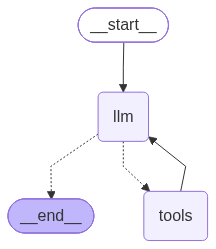

================================ Human Message =================================

杭州和上海天气如何？
================================== Ai Message ==================================
Tool Calls:
  get_weather (call_00_QZBXOqQXfvBd6JNUWPkj6162)
 Call ID: call_00_QZBXOqQXfvBd6JNUWPkj6162
  Args:
    city: 杭州
  get_weather (call_01_lmwpmuoe4MXzADn5lMtT5452)
 Call ID: call_01_lmwpmuoe4MXzADn5lMtT5452
  Args:
    city: 上海
================================= Tool Message =================================

小雨 22度
================================= Tool Message =================================

多云 28度
================================== Ai Message ==================================

杭州和上海的天气如下：

- **杭州**：小雨，22°C
- **上海**：多云，28°C

杭州有雨，出门记得带伞；上海多云比较舒适，两地温差约 6°C。


In [11]:
from typing import Literal

from dotenv import load_dotenv
from IPython.core.display import Image
from langchain.chat_models import init_chat_model
from langchain_core.messages import HumanMessage, ToolMessage
from langchain_core.tools import tool
from langgraph.constants import END, START
from langgraph.graph import MessagesState, StateGraph

load_dotenv(override=True)


# ====== Step 1: 准备工具 ======
@tool
def get_weather(city: str) -> str:
    """获取城市天气"""
    weather_data = {
        "北京": "晴天 25度",
        "上海": "多云 28度",
        "杭州": "小雨 22度",
    }
    return weather_data.get(city, f"未找到{city}的天气信息")


@tool
def square_root(x: float) -> str:
    """Calculate the square root of a number"""
    return x**0.5


# 组成工具数组
tools = [get_weather, square_root]
# 组成工具名和工具的映射，方便查找工具
tools_by_name = {t.name: t for t in tools}

# ====== Step 2: 准备模型，绑定工具 ======
model = init_chat_model("deepseek-flash", extra_body={"thinking": {"type": "disabled"}})

# 绑定工具到模型，与create_agent类似，将来LangChain会自动帮我们拼接tool信息发给模型
model_with_tools = model.bind_tools(tools)


# ====== Step 3: 定义Node ======
def tool_node(state: MessagesState):
    # 获取最后一条消息，也就是AI返回的带工具的消息
    message = state["messages"][-1]
    tool_messages = []
    """
    AIMessage(
        content='',
        id='lc_run--01a1e81a-6221-77cf-b3d1-578d4388fee1-0',
        tool_calls=[
            {
                'name': 'get_weather',
                'args': {'city': '杭州'},
                'id': 'call_00_OwexQxTU088OvPKPV0Xy1856',
                'type': 'tool_call'
            },
            {
                'name': 'get_weather',
                'args': {'city': '上海'},
                'id': 'call_01_Re4VNIfJE7niXl1bQf1R4029',
                'type': 'tool_call'
            }
        ],
    )
    """
    # 获取工具, 逐个处理
    for tool_call in message.tool_calls:
        tool_name = tool_call["name"]
        tool_args = tool_call["args"]
        # 调用工具
        result = tools_by_name[tool_name].invoke(tool_args)
        # 封装ToolMessage
        tool_messages.append(ToolMessage(content=result, tool_call_id=tool_call["id"]))

    # 返回结果
    return {"messages": tool_messages}


# res = model_with_tools.invoke("杭州和上海天气如何")
# rich_print(res)


def llm_node(state: MessagesState):
    """LLM节点：调用模型，可以选择调用工具"""
    response = model_with_tools.invoke(state["messages"])
    return {"messages": [response]}


# 要定义路由，就是看AI返回消息中是否带有tool_call，有就走tool_node，没有就走END
def should_continue(state: MessagesState) -> Literal["tools", END]:
    """路由函数：判断下一步是继续调工具还是结束"""
    last_message = state["messages"][-1]
    # 如果包含tool_calls，则跳转到tools节点，没有则跳转到END节点
    if hasattr(last_message, "tool_calls") and last_message.tool_calls:
        return "tools"  # 有工具调用 -> 去工具节点，调用工具
    return END  # 没有有工具调用 -> 去END，直接返回AI消息给用户


# 4.添加Edge，连接Node，形成Graph
builder = StateGraph(MessagesState)
builder.add_node("tools", tool_node)
builder.add_node("llm", llm_node)

builder.add_edge(START, "llm")
builder.add_conditional_edges("llm", should_continue)
builder.add_edge("tools", "llm")

graph = builder.compile()  # 3.4.编译成可执行图
display(Image(graph.get_graph(xray=True).draw_mermaid_png()))

# ===================4.调用graph======================
response = graph.invoke(
    {
        "messages": [
            # HumanMessage(content="一句话介绍你自己？"),
            HumanMessage(content="杭州和上海天气如何？"),
        ]
    }
)
for message in response["messages"]:
    message.pretty_print()